### Notebook 02: Pembagian Dataset Berdasarkan Foto Sumber

#### 1. Persiapan

##### 1.1 Pustaka

In [1]:
import hashlib
import json
import platform
import sys
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import StratifiedGroupKFold

print("Python       :", platform.python_version())
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)

Python       : 3.10.6
NumPy        : 1.26.4
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.2


##### 1.2 Konfigurasi

In [2]:
def find_ml_dir(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "data" / "processed").exists() and (folder / "notebooks").exists():
            return folder
        if (folder / "ml" / "data" / "processed").exists():
            return folder / "ml"
    raise FileNotFoundError("Folder ml/ tidak ditemukan. Buka notebook ini dari dalam repo Nutrify.")


ML_DIR = find_ml_dir(Path.cwd().resolve())

SEED = 42
N_FOLDS = 5
TEST_FRACTION = 0.20
REPEAT_SEEDS = (42, 43, 44)
MIN_GROUPS_PER_CLASS = 15
MIN_TEST_GROUPS_PER_CLASS = 3

PROCESSED_DIR = ML_DIR / "data" / "processed"
FIGURES_DIR = ML_DIR / "reports" / "figures"
TABLES_DIR = ML_DIR / "reports" / "tables"
for folder in (FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

FEATURES_PATH = PROCESSED_DIR / "features.csv"
SPLITS_PATH = PROCESSED_DIR / "splits.csv"

CLASSES = ("normal", "n_deficiency", "fe_deficiency")
CLASS_LABEL_ID = {"normal": "Normal", "n_deficiency": "Defisiensi N", "fe_deficiency": "Defisiensi Fe"}
CLASS_COLORS = {"normal": "#009E73", "n_deficiency": "#E69F00", "fe_deficiency": "#CC79A7"}
FEATURES_A2 = ["Mean_R", "Mean_G", "Mean_B", "Lab_L", "Lab_a", "Lab_b"]
FOLD_COLUMNS = [f"fold_r{index + 1}" for index in range(len(REPEAT_SEEDS))]

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / name, bbox_inches="tight")


print("Folder ml/ :", ML_DIR)

Folder ml/ : D:\LARAGON\www\nutrify\ml


#### 2. Data Masukan

##### 2.1 Pemuatan features.csv

In [3]:
features = pd.read_csv(FEATURES_PATH)
required_columns = ["image_id", "source_group", "label", "origin", "qc_status", *FEATURES_A2]
missing_columns = [column for column in required_columns if column not in features.columns]
assert not missing_columns, f"Kolom tidak ditemukan: {missing_columns}"
assert features["image_id"].is_unique, "image_id tidak unik"

print("Jumlah baris :", len(features))
display(features.groupby(["origin", "qc_status"]).size().rename("jumlah").to_frame())

Jumlah baris : 388


,,jumlah
origin,qc_status,
primary,ok,8
roboflow,ok,380


##### 2.2 Pemisahan data Roboflow dan foto primer

In [4]:
valid = features[features["qc_status"] == "ok"].copy()
pool = valid[valid["origin"] == "roboflow"].reset_index(drop=True)
primary = valid[valid["origin"] == "primary"].reset_index(drop=True)

print("Roboflow valid :", len(pool))
print("Primer valid   :", len(primary))
print("Dikeluarkan QC :", int((features["qc_status"] != "ok").sum()))

Roboflow valid : 380
Primer valid   : 8
Dikeluarkan QC : 0


#### 3. Audit Foto Sumber

##### 3.1 Berkas dan foto sumber per kelas

In [5]:
group_sizes = pool.groupby(["label", "source_group"]).size().rename("berkas").reset_index()

audit = (
    group_sizes.groupby("label")["berkas"]
    .agg(foto_sumber="size", berkas="sum", min_per_foto="min", median_per_foto="median", maks_per_foto="max")
    .reindex(CLASSES)
)
audit["porsi_berkas"] = (audit["berkas"] / audit["berkas"].sum()).round(4)
audit["porsi_foto_sumber"] = (audit["foto_sumber"] / audit["foto_sumber"].sum()).round(4)
audit.index = [CLASS_LABEL_ID[c] for c in audit.index]
audit.to_csv(TABLES_DIR / "02_group_audit.csv")
display(audit)

,foto_sumber,berkas,min_per_foto,median_per_foto,maks_per_foto,porsi_berkas,porsi_foto_sumber
Normal,72,112,1,1.0,6,0.2947,0.5294
Defisiensi N,20,92,1,6.0,6,0.2421,0.1471
Defisiensi Fe,44,176,1,6.0,6,0.4632,0.3235


##### 3.2 Distribusi berkas per foto sumber

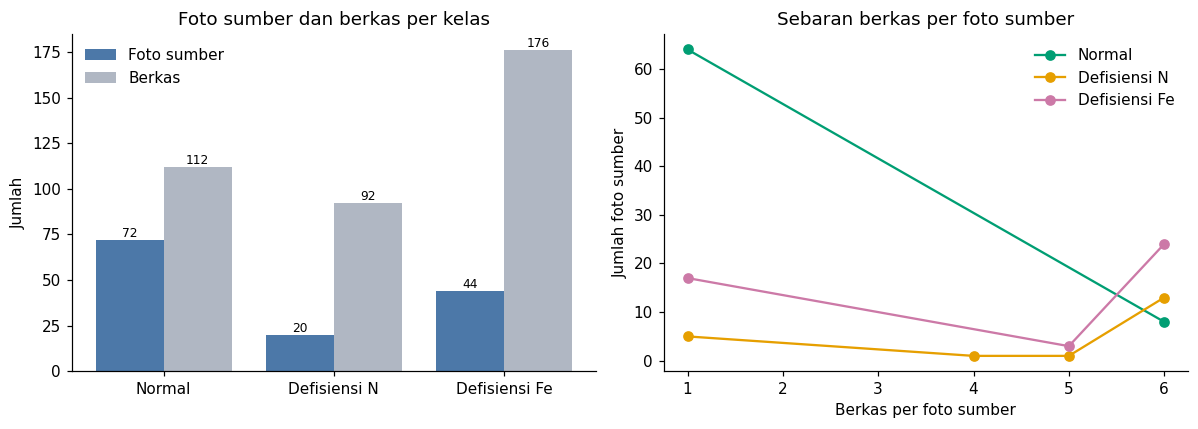

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

positions = np.arange(len(CLASSES))
axes[0].bar(positions - 0.2, [audit.iloc[i]["foto_sumber"] for i in range(3)], 0.4, label="Foto sumber", color="#4C78A8")
axes[0].bar(positions + 0.2, [audit.iloc[i]["berkas"] for i in range(3)], 0.4, label="Berkas", color="#B0B7C3")
axes[0].set_xticks(positions, [CLASS_LABEL_ID[c] for c in CLASSES])
axes[0].set_ylabel("Jumlah")
axes[0].set_title("Foto sumber dan berkas per kelas")
axes[0].legend(frameon=False)
for x, c in zip(positions, CLASSES):
    axes[0].text(x - 0.2, audit.loc[CLASS_LABEL_ID[c], "foto_sumber"], int(audit.loc[CLASS_LABEL_ID[c], "foto_sumber"]), ha="center", va="bottom", fontsize=8)
    axes[0].text(x + 0.2, audit.loc[CLASS_LABEL_ID[c], "berkas"], int(audit.loc[CLASS_LABEL_ID[c], "berkas"]), ha="center", va="bottom", fontsize=8)

for c in CLASSES:
    counts = group_sizes[group_sizes["label"] == c]["berkas"].value_counts().sort_index()
    axes[1].plot(counts.index, counts.values, marker="o", color=CLASS_COLORS[c], label=CLASS_LABEL_ID[c])
axes[1].set_xlabel("Berkas per foto sumber")
axes[1].set_ylabel("Jumlah foto sumber")
axes[1].set_title("Sebaran berkas per foto sumber")
axes[1].legend(frameon=False)

fig.tight_layout()
save_figure(fig, "02_group_audit.png")
plt.show()

#### 4. Strategi Pembagian

##### 4.1 Aturan keputusan

Jumlah foto sumber kelas $c$ dinotasikan $G_c$. Jumlah foto sumber kelas $c$ yang diharapkan berada di data uji:

$$
E_c = \tau \, G_c, \qquad \tau = 0{,}20
$$

Strategi pembagian ditentukan dari jumlah foto sumber, sebelum model apa pun dilatih:

$$
\text{strategi} =
\begin{cases}
\text{hold-out 80/20 + CV 5-lipatan} & \min_c G_c \ge 15 \\
\text{nested CV} & \min_c G_c < 15
\end{cases}
$$

In [7]:
groups_per_class = pool.groupby("label")["source_group"].nunique().reindex(CLASSES)
expected_test_groups = (TEST_FRACTION * groups_per_class).round(2)

decision = pd.DataFrame(
    {
        "G_c": groups_per_class,
        "E_c_uji": expected_test_groups,
        "G_c >= 15": groups_per_class >= MIN_GROUPS_PER_CLASS,
    }
)
decision.index = [CLASS_LABEL_ID[c] for c in decision.index]
display(decision)

STRATEGY = "holdout" if bool((groups_per_class >= MIN_GROUPS_PER_CLASS).all()) else "nested"
print("Strategi terpilih :", STRATEGY)

if STRATEGY != "holdout":
    raise RuntimeError("Jumlah foto sumber kurang dari 15 pada sedikitnya satu kelas: gunakan nested CV (ML.md bagian 7.3).")

,G_c,E_c_uji,G_c >= 15
Normal,72,14.4,True
Defisiensi N,20,4.0,True
Defisiensi Fe,44,8.8,True


Strategi terpilih : holdout


#### 5. Data Uji (Hold-out 20%)

##### 5.1 Kandidat lipatan

Data Roboflow dibagi menjadi lima lipatan berkelompok bertingkat. Kandidat data uji adalah satu lipatan. Untuk lipatan $k$, penyimpangan proporsi kelas terhadap proporsi seluruh data:

$$
D_k = \max_{c} \left| p_c^{(k)} - p_c \right|, \qquad p_c = \frac{n_c}{n}
$$

Lipatan terpilih adalah $k^{*} = \arg\min_k D_k$ di antara lipatan dengan sedikitnya tiga foto sumber pada setiap kelas. Kriteria hanya memakai label dan kelompok, tidak memakai fitur atau hasil model.

In [8]:
def class_share(frame: pd.DataFrame) -> pd.Series:
    return frame["label"].value_counts(normalize=True).reindex(CLASSES).fillna(0.0)


overall_share = class_share(pool)
splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

candidates = []
candidate_indices = []
for k, (train_idx, test_idx) in enumerate(splitter.split(pool, pool["label"], pool["source_group"])):
    test_part = pool.iloc[test_idx]
    share = class_share(test_part)
    test_groups = test_part.groupby("label")["source_group"].nunique().reindex(CLASSES).fillna(0).astype(int)
    candidate_indices.append((train_idx, test_idx))
    candidates.append(
        {
            "lipatan": k,
            "berkas_uji": len(test_part),
            "porsi_uji": round(len(test_part) / len(pool), 4),
            **{f"foto_{c}": int(test_groups[c]) for c in CLASSES},
            **{f"selisih_{c}": round(float(abs(share[c] - overall_share[c])), 4) for c in CLASSES},
            "D_k": round(float((share - overall_share).abs().max()), 4),
            "memenuhi_minimum": bool((test_groups >= MIN_TEST_GROUPS_PER_CLASS).all()),
        }
    )

candidate_table = pd.DataFrame(candidates).set_index("lipatan")
candidate_table.to_csv(TABLES_DIR / "02_holdout_candidates.csv")
display(candidate_table)

,berkas_uji,porsi_uji,foto_normal,foto_n_deficiency,foto_fe_deficiency,selisih_normal,selisih_n_deficiency,selisih_fe_deficiency,D_k,memenuhi_minimum
lipatan,,,,,,,,,,
0,81,0.2132,13,4,10,0.0108,0.0693,0.0801,0.0801,True
1,76,0.2000,15,4,9,0.0316,0.0474,0.0158,0.0474,True
2,53,0.1395,14,4,5,0.0638,0.1164,0.1801,0.1801,True
3,80,0.2105,15,5,8,0.0178,0.0579,0.0757,0.0757,True
4,90,0.2368,15,3,12,0.0170,0.0977,0.1146,0.1146,True


##### 5.2 Pemilihan lipatan uji

In [9]:
eligible = candidate_table[candidate_table["memenuhi_minimum"]]
assert len(eligible) > 0, "Tidak ada lipatan dengan minimal tiga foto sumber per kelas"
CHOSEN_FOLD = int(eligible["D_k"].idxmin())
train_idx, test_idx = candidate_indices[CHOSEN_FOLD]

pool["partition"] = "train"
pool.loc[test_idx, "partition"] = "test"

print("Lipatan terpilih :", CHOSEN_FOLD)
print("D_k              :", candidate_table.loc[CHOSEN_FOLD, "D_k"])
display(pool.groupby(["partition", "label"]).agg(berkas=("image_id", "size"), foto_sumber=("source_group", "nunique")).unstack("partition"))

Lipatan terpilih : 1
D_k              : 0.0474


berkas       foto_sumber      
partition       test train        test train
label                                       
fe_deficiency     34   142           9    35
n_deficiency      22    70           4    16
normal            20    92          15    57

##### 5.3 Verifikasi tidak ada foto sumber di kedua sisi

In [10]:
train_groups = set(pool.loc[pool["partition"] == "train", "source_group"])
test_groups = set(pool.loc[pool["partition"] == "test", "source_group"])
overlap = train_groups & test_groups

print("Foto sumber latih :", len(train_groups))
print("Foto sumber uji   :", len(test_groups))
print("Irisan            :", len(overlap))
assert not overlap, f"Kebocoran: {sorted(overlap)[:5]}"

partition_summary = (
    pool.groupby(["partition", "label"])
    .agg(berkas=("image_id", "size"), foto_sumber=("source_group", "nunique"))
    .reset_index()
)
partition_summary["label"] = partition_summary["label"].map(CLASS_LABEL_ID)
partition_summary.to_csv(TABLES_DIR / "02_partition_summary.csv", index=False)

Foto sumber latih : 108
Foto sumber uji   : 28
Irisan            : 0


#### 6. Lipatan Validasi Silang pada Data Latih

##### 6.1 Pembentukan lipatan

Validasi silang 5-lipatan berkelompok bertingkat diulang tiga kali dengan benih $s \in \{42, 43, 44\}$. Pada setiap pengulangan, setiap foto sumber menjadi data validasi tepat satu kali:

$$
\forall g:\ \left|\{k : g \in V_k^{(s)}\}\right| = 1, \qquad
T_k^{(s)} \cap V_k^{(s)} = \varnothing \ \text{pada tingkat foto sumber}
$$

In [11]:
train_part = pool[pool["partition"] == "train"].copy()

for column, seed in zip(FOLD_COLUMNS, REPEAT_SEEDS):
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    fold_of_row = np.full(len(train_part), -1, dtype=int)
    for fold, (_, validation_idx) in enumerate(cv.split(train_part, train_part["label"], train_part["source_group"])):
        fold_of_row[validation_idx] = fold
    assert (fold_of_row >= 0).all()
    train_part[column] = fold_of_row

pool = pool.merge(train_part[["image_id", *FOLD_COLUMNS]], on="image_id", how="left")
for column in FOLD_COLUMNS:
    pool[column] = pool[column].astype("Int64")

print("Baris latih dengan lipatan :", int(pool[FOLD_COLUMNS[0]].notna().sum()))

Baris latih dengan lipatan : 304


##### 6.2 Verifikasi lipatan

In [12]:
checks = []
for column, seed in zip(FOLD_COLUMNS, REPEAT_SEEDS):
    frame = pool[pool["partition"] == "train"]
    one_fold_per_group = bool((frame.groupby("source_group")[column].nunique() == 1).all())
    all_folds_present = sorted(frame[column].unique().tolist()) == list(range(N_FOLDS))
    per_fold_class_groups = frame.groupby([column, "label"])["source_group"].nunique().unstack().reindex(columns=list(CLASSES)).fillna(0)
    every_class_in_every_fold = bool((per_fold_class_groups >= 1).all().all())
    checks.append(
        {
            "pengulangan": column,
            "seed": seed,
            "satu_lipatan_per_foto_sumber": one_fold_per_group,
            "lima_lipatan_terisi": all_folds_present,
            "setiap_kelas_ada_di_setiap_lipatan": every_class_in_every_fold,
            "min_foto_sumber_per_kelas_lipatan": int(per_fold_class_groups.min().min()),
        }
    )
    assert one_fold_per_group and all_folds_present and every_class_in_every_fold

check_table = pd.DataFrame(checks).set_index("pengulangan")
check_table.to_csv(TABLES_DIR / "02_cv_checks.csv")
display(check_table)

,seed,satu_lipatan_per_foto_sumber,lima_lipatan_terisi,setiap_kelas_ada_di_setiap_lipatan,min_foto_sumber_per_kelas_lipatan
pengulangan,,,,,
fold_r1,42,True,True,True,2
fold_r2,43,True,True,True,3
fold_r3,44,True,True,True,2


##### 6.3 Komposisi lipatan

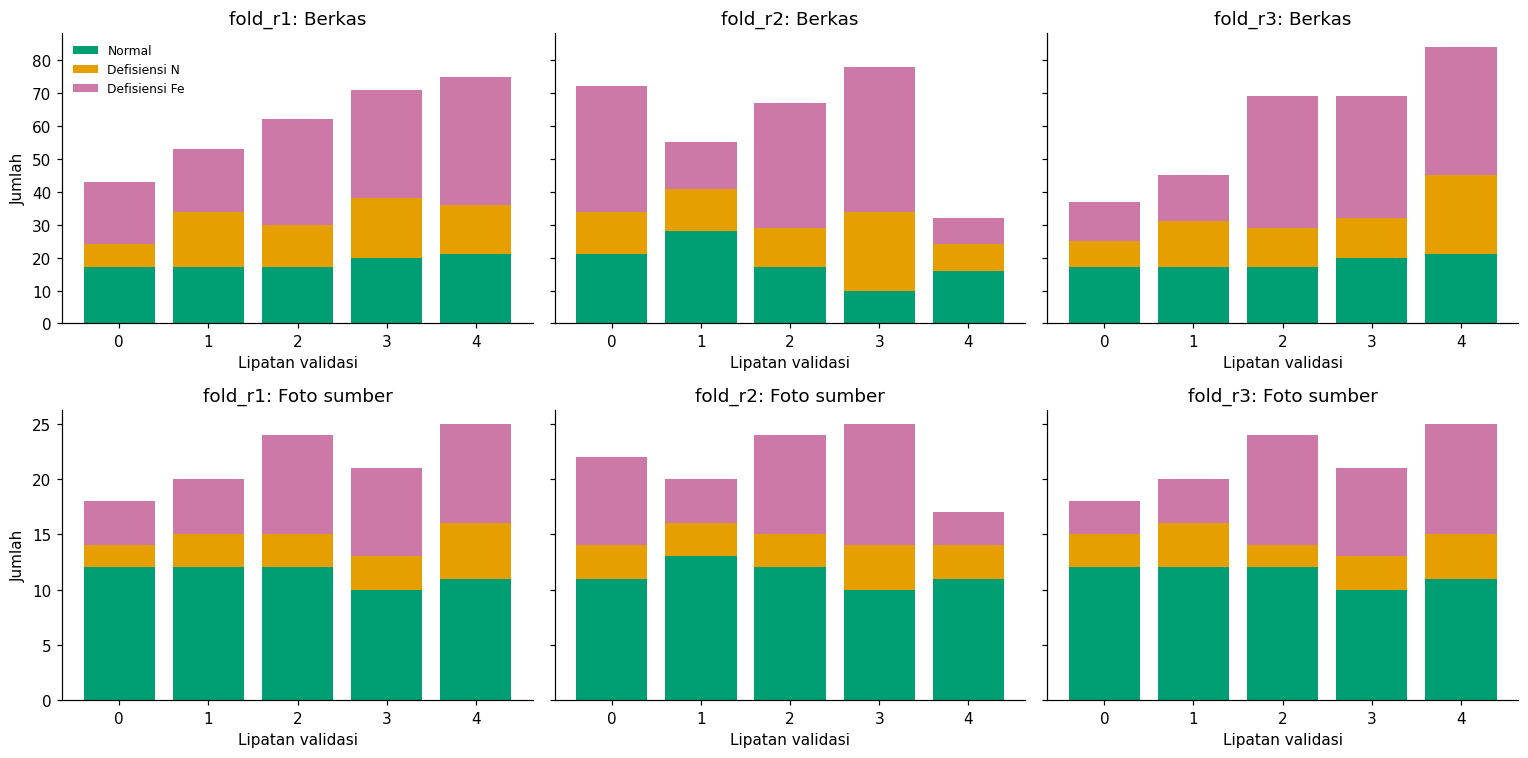

In [13]:
composition_rows = []
for column in FOLD_COLUMNS:
    frame = pool[pool["partition"] == "train"]
    table = frame.groupby([column, "label"]).agg(berkas=("image_id", "size"), foto_sumber=("source_group", "nunique")).reset_index()
    table = table.rename(columns={column: "lipatan"})
    table.insert(0, "pengulangan", column)
    composition_rows.append(table)
composition = pd.concat(composition_rows, ignore_index=True)
composition["label"] = composition["label"].map(CLASS_LABEL_ID)
composition.to_csv(TABLES_DIR / "02_cv_fold_composition.csv", index=False)

fig, axes = plt.subplots(2, len(FOLD_COLUMNS), figsize=(14, 7), sharey="row")
for col, column in enumerate(FOLD_COLUMNS):
    subset = composition[composition["pengulangan"] == column]
    for row, (measure, title) in enumerate((("berkas", "Berkas"), ("foto_sumber", "Foto sumber"))):
        pivot = subset.pivot(index="lipatan", columns="label", values=measure).reindex(columns=[CLASS_LABEL_ID[c] for c in CLASSES])
        bottom = np.zeros(len(pivot))
        for c in CLASSES:
            values = pivot[CLASS_LABEL_ID[c]].to_numpy()
            axes[row, col].bar(pivot.index, values, bottom=bottom, color=CLASS_COLORS[c], label=CLASS_LABEL_ID[c])
            bottom += values
        axes[row, col].set_title(f"{column}: {title}")
        axes[row, col].set_xlabel("Lipatan validasi")
        if col == 0:
            axes[row, col].set_ylabel("Jumlah")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "02_cv_fold_composition.png")
plt.show()

#### 7. Pemeriksaan Kemiripan Lintas Partisi

##### 7.1 Jarak terdekat dalam ruang fitur

Fitur dibakukan dengan rata-rata dan simpangan baku data latih. Jarak Euclid antara dua citra $x$ dan $y$:

$$
d(x, y) = \sqrt{\sum_{j=1}^{6} \left( \frac{x_j - y_j}{s_j} \right)^2}
$$

Tiga jarak terdekat dibandingkan untuk setiap citra: ke citra lain dari foto sumber yang sama (salinan augmentasi), ke citra latih dari foto sumber lain, dan, untuk citra uji, ke citra latih.

In [14]:
train_frame = pool[pool["partition"] == "train"].reset_index(drop=True)
test_frame = pool[pool["partition"] == "test"].reset_index(drop=True)

mean = train_frame[FEATURES_A2].mean()
scale = train_frame[FEATURES_A2].std(ddof=0).replace(0, 1.0)


def standardize(frame: pd.DataFrame) -> np.ndarray:
    return ((frame[FEATURES_A2] - mean) / scale).to_numpy(dtype=float)


def pairwise_distance(first: np.ndarray, second: np.ndarray) -> np.ndarray:
    diff = first[:, None, :] - second[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=2))


train_z = standardize(train_frame)
test_z = standardize(test_frame)
train_groups_array = train_frame["source_group"].to_numpy()

train_distance = pairwise_distance(train_z, train_z)
np.fill_diagonal(train_distance, np.inf)
same_group = train_groups_array[:, None] == train_groups_array[None, :]

nearest_same_group = np.where(same_group, train_distance, np.inf).min(axis=1)
nearest_other_group = np.where(~same_group, train_distance, np.inf).min(axis=1)
nearest_test_to_train = pairwise_distance(test_z, train_z).min(axis=1)

has_sibling = np.isfinite(nearest_same_group)
distances = {
    "Salinan foto sumber yang sama (latih)": nearest_same_group[has_sibling],
    "Foto sumber lain (latih ke latih)": nearest_other_group,
    "Uji ke latih": nearest_test_to_train,
}

distance_summary = pd.DataFrame(
    {
        name: {
            "n": len(values),
            "persentil_5": np.percentile(values, 5),
            "median": np.median(values),
            "persentil_95": np.percentile(values, 95),
        }
        for name, values in distances.items()
    }
).T.round(4)
distance_summary.to_csv(TABLES_DIR / "02_nearest_distance_summary.csv")
display(distance_summary)

,n,persentil_5,median,persentil_95
Salinan foto sumber yang sama (latih),236.0,0.2387,0.8718,2.0053
Foto sumber lain (latih ke latih),304.0,0.1009,0.3800,0.9875
Uji ke latih,76.0,0.0885,0.3444,0.8938


##### 7.2 Kurva distribusi kumulatif jarak terdekat

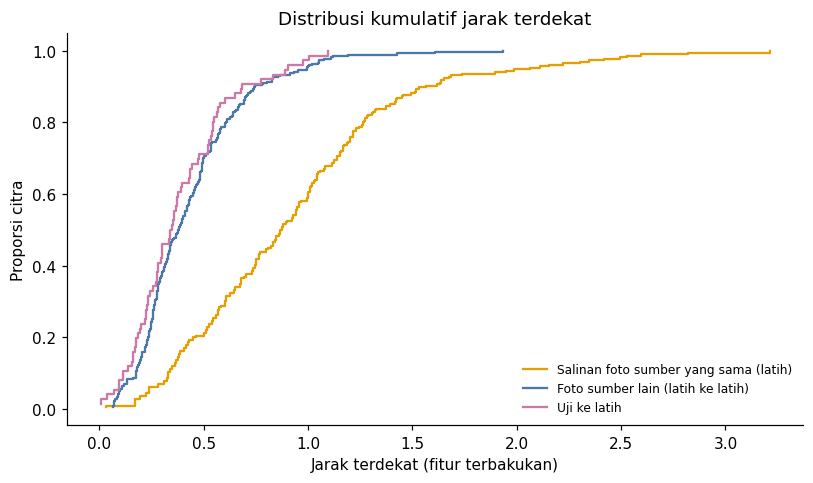

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
palette = {"Salinan foto sumber yang sama (latih)": "#E69F00", "Foto sumber lain (latih ke latih)": "#4C78A8", "Uji ke latih": "#CC79A7"}
for name, values in distances.items():
    ordered = np.sort(values)
    ax.step(ordered, np.arange(1, len(ordered) + 1) / len(ordered), where="post", label=name, color=palette[name])
ax.set_xlabel("Jarak terdekat (fitur terbakukan)")
ax.set_ylabel("Proporsi citra")
ax.set_title("Distribusi kumulatif jarak terdekat")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "02_nearest_distance_ecdf.png")
plt.show()

##### 7.3 Proporsi citra uji yang lebih dekat dari batas acuan

Batas acuan $d_{\text{ref}}$ adalah persentil ke-5 jarak terdekat citra latih ke citra latih dari foto sumber lain. Bila citra uji tidak lebih mirip dengan data latih daripada foto sumber latih satu sama lain, proporsi berikut mendekati $0{,}05$:

$$
\hat{p} = \frac{1}{n_{\text{uji}}} \sum_{x \in \text{uji}} \mathbb{1}\left[ \min_{y \in \text{latih}} d(x, y) \le d_{\text{ref}} \right]
$$

Perbedaan distribusi diuji dengan uji Kolmogorov-Smirnov dua sampel antara jarak uji ke latih dan jarak latih ke foto sumber lain.

In [16]:
from scipy.stats import ks_2samp

reference_distance = float(np.percentile(nearest_other_group, 5))
test_frame["nearest_train_distance"] = nearest_test_to_train
test_frame["below_reference"] = test_frame["nearest_train_distance"] <= reference_distance

below_reference_table = (
    test_frame.groupby("label")
    .agg(berkas_uji=("image_id", "size"), di_bawah_acuan=("below_reference", "sum"), median_jarak=("nearest_train_distance", "median"))
    .reindex(CLASSES)
)
below_reference_table["proporsi"] = (below_reference_table["di_bawah_acuan"] / below_reference_table["berkas_uji"]).round(4)
below_reference_table.index = [CLASS_LABEL_ID[c] for c in below_reference_table.index]
below_reference_table.to_csv(TABLES_DIR / "02_test_below_reference.csv")

ks_result = ks_2samp(nearest_test_to_train, nearest_other_group)
test_below_reference_share = float(test_frame["below_reference"].mean())

print("Batas acuan d_ref        :", round(reference_distance, 4))
print("Proporsi uji <= d_ref    :", round(test_below_reference_share, 4), "(harapan tanpa kebocoran: sekitar 0,05)")
print("KS statistik / p-value   :", round(float(ks_result.statistic), 4), "/", round(float(ks_result.pvalue), 4))
display(below_reference_table.round(4))

Batas acuan d_ref        : 0.1009
Proporsi uji <= d_ref    : 0.0789 (harapan tanpa kebocoran: sekitar 0,05)
KS statistik / p-value   : 0.1217 / 0.314


,berkas_uji,di_bawah_acuan,median_jarak,proporsi
Normal,20,5,0.2158,0.2500
Defisiensi N,22,1,0.5458,0.0455
Defisiensi Fe,34,0,0.2997,0.0000


##### 7.4 Berkas identik lintas foto sumber

In [17]:
manifest = pd.read_csv(PROCESSED_DIR / "manifest.csv")
manifest = manifest[(manifest["origin"] == "roboflow") & manifest["image_id"].isin(pool["image_id"])]

sha1_groups = manifest.groupby("sha1")["source_group"].nunique()
identical_across_groups = sha1_groups[sha1_groups > 1]

print("Berkas dengan isi identik di lebih dari satu foto sumber :", len(identical_across_groups))
assert len(identical_across_groups) == 0, manifest[manifest["sha1"].isin(identical_across_groups.index)][["image_id", "source_group"]]

Berkas dengan isi identik di lebih dari satu foto sumber : 0


#### 8. Foto Primer

##### 8.1 Partisi eksternal

In [18]:
external = primary[["image_id", "source_group", "label"]].copy()
external["partition"] = "external"
for column in FOLD_COLUMNS:
    external[column] = pd.array([pd.NA] * len(external), dtype="Int64")

print("Foto primer :", len(external))
display(external.groupby(["label", "source_group"]).size().rename("berkas").to_frame())

Foto primer : 8


,,berkas
label,source_group,
normal,primary,8


#### 9. Penyimpanan Hasil

##### 9.1 splits.csv

In [19]:
splits = pd.concat(
    [pool[["image_id", "source_group", "label", "partition", *FOLD_COLUMNS]], external[["image_id", "source_group", "label", "partition", *FOLD_COLUMNS]]],
    ignore_index=True,
)
partition_order = {"train": 0, "test": 1, "external": 2}
splits = splits.sort_values(["partition", "label", "source_group", "image_id"], key=lambda s: s.map(partition_order) if s.name == "partition" else s).reset_index(drop=True)

assert splits["image_id"].is_unique
assert set(splits["partition"]) == {"train", "test", "external"}
assert splits.loc[splits["partition"] != "train", FOLD_COLUMNS].isna().all().all()
assert splits.loc[splits["partition"] == "train", FOLD_COLUMNS].notna().all().all()

splits.to_csv(SPLITS_PATH, index=False)
print("Disimpan :", SPLITS_PATH, "|", len(splits), "baris")
display(splits.groupby(["partition", "label"]).size().unstack(fill_value=0))

Disimpan : D:\LARAGON\www\nutrify\ml\data\processed\splits.csv | 388 baris


label,fe_deficiency,n_deficiency,normal
partition,,,
external,0,0,8
test,34,22,20
train,142,70,92


##### 9.2 split_params.json

In [20]:
split_params = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "features_sha1": hashlib.sha1(FEATURES_PATH.read_bytes()).hexdigest(),
    "sklearn": sklearn.__version__,
    "strategy": STRATEGY,
    "seed": SEED,
    "n_folds": N_FOLDS,
    "test_fraction": TEST_FRACTION,
    "repeat_seeds": list(REPEAT_SEEDS),
    "min_groups_per_class": MIN_GROUPS_PER_CLASS,
    "min_test_groups_per_class": MIN_TEST_GROUPS_PER_CLASS,
    "chosen_holdout_fold": CHOSEN_FOLD,
    "holdout_deviation_D_k": float(candidate_table.loc[CHOSEN_FOLD, "D_k"]),
    "groups_per_class": {c: int(groups_per_class[c]) for c in CLASSES},
    "partition_counts": {
        part: {
            c: {
                "files": int(((splits["partition"] == part) & (splits["label"] == c)).sum()),
                "groups": int(splits.loc[(splits["partition"] == part) & (splits["label"] == c), "source_group"].nunique()),
            }
            for c in CLASSES
        }
        for part in ("train", "test", "external")
    },
    "reference_distance_d_ref": round(reference_distance, 4),
    "test_below_reference_share": round(test_below_reference_share, 4),
    "ks_statistic": round(float(ks_result.statistic), 4),
    "ks_pvalue": round(float(ks_result.pvalue), 4),
    "identical_files_across_groups": int(len(identical_across_groups)),
}
(PROCESSED_DIR / "split_params.json").write_text(json.dumps(split_params, indent=2), encoding="utf-8")
print(json.dumps(split_params, indent=2))

{
  "created_at": "2026-11-19T14:01:34",
  "features_sha1": "b99f19dd22302bf9ad372c6e7e9a7276e28d11f3",
  "sklearn": "1.5.2",
  "strategy": "holdout",
  "seed": 42,
  "n_folds": 5,
  "test_fraction": 0.2,
  "repeat_seeds": [
    42,
    43,
    44
  ],
  "min_groups_per_class": 15,
  "min_test_groups_per_class": 3,
  "chosen_holdout_fold": 1,
  "holdout_deviation_D_k": 0.0474,
  "groups_per_class": {
    "normal": 72,
    "n_deficiency": 20,
    "fe_deficiency": 44
  },
  "partition_counts": {
    "train": {
      "normal": {
        "files": 92,
        "groups": 57
      },
      "n_deficiency": {
        "files": 70,
        "groups": 16
      },
      "fe_deficiency": {
        "files": 142,
        "groups": 35
      }
    },
    "test": {
      "normal": {
        "files": 20,
        "groups": 15
      },
      "n_deficiency": {
        "files": 22,
        "groups": 4
      },
      "fe_deficiency": {
        "files": 34,
        "groups": 9
      }
    },
    "external": {
   

##### 9.3 Ringkasan akhir

In [21]:
final_summary = pd.DataFrame(
    [
        ("Strategi", STRATEGY),
        ("Lipatan uji terpilih", CHOSEN_FOLD),
        ("Berkas latih", int((splits["partition"] == "train").sum())),
        ("Berkas uji", int((splits["partition"] == "test").sum())),
        ("Berkas eksternal (primer)", int((splits["partition"] == "external").sum())),
        ("Foto sumber latih", len(train_groups)),
        ("Foto sumber uji", len(test_groups)),
        ("Irisan foto sumber latih dan uji", len(overlap)),
        ("Proporsi uji <= d_ref (harapan sekitar 0,05)", split_params["test_below_reference_share"]),
        ("p-value KS uji ke latih vs latih ke foto sumber lain", split_params["ks_pvalue"]),
        ("Berkas identik lintas foto sumber", split_params["identical_files_across_groups"]),
    ],
    columns=["item", "nilai"],
)
final_summary.to_csv(TABLES_DIR / "02_final_summary.csv", index=False)
display(final_summary)

,item,nilai
0,Strategi,holdout
1,Lipatan uji terpilih,1
2,Berkas latih,304
3,Berkas uji,76
4,Berkas eksternal (primer),8
5,Foto sumber latih,108
6,Foto sumber uji,28
7,Irisan foto sumber latih dan uji,0
8,"Proporsi uji <= d_ref (harapan sekitar 0,05)",0.0789
9,p-value KS uji ke latih vs latih ke foto sumbe...,0.314
